In [ ]:
!pip install tensorflow pandas numpy matplotlib seaborn opencv-python

In [6]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz

!tar -xzf imagenette2-160.tgz

dataset_path = "/content/imagenette2-160/train"

print("Imagenette dataset downloaded successfully!")

Imagenette dataset downloaded successfully!


In [20]:
classes = sorted(os.listdir(dataset_path))

print("Total Classes:", len(classes))
print("\nAvailable Classes:")

for name in classes:
    folder = os.path.join(dataset_path, name)
    if os.path.isdir(folder):
        print(name, ":", len(os.listdir(folder)), "images")

Total Classes: 11

Available Classes:
n01440764 : 963 images
n02102040 : 955 images
n02979186 : 993 images
n03000684 : 858 images
n03028079 : 941 images
n03394916 : 956 images
n03417042 : 961 images
n03425413 : 931 images
n03445777 : 951 images
n03888257 : 960 images


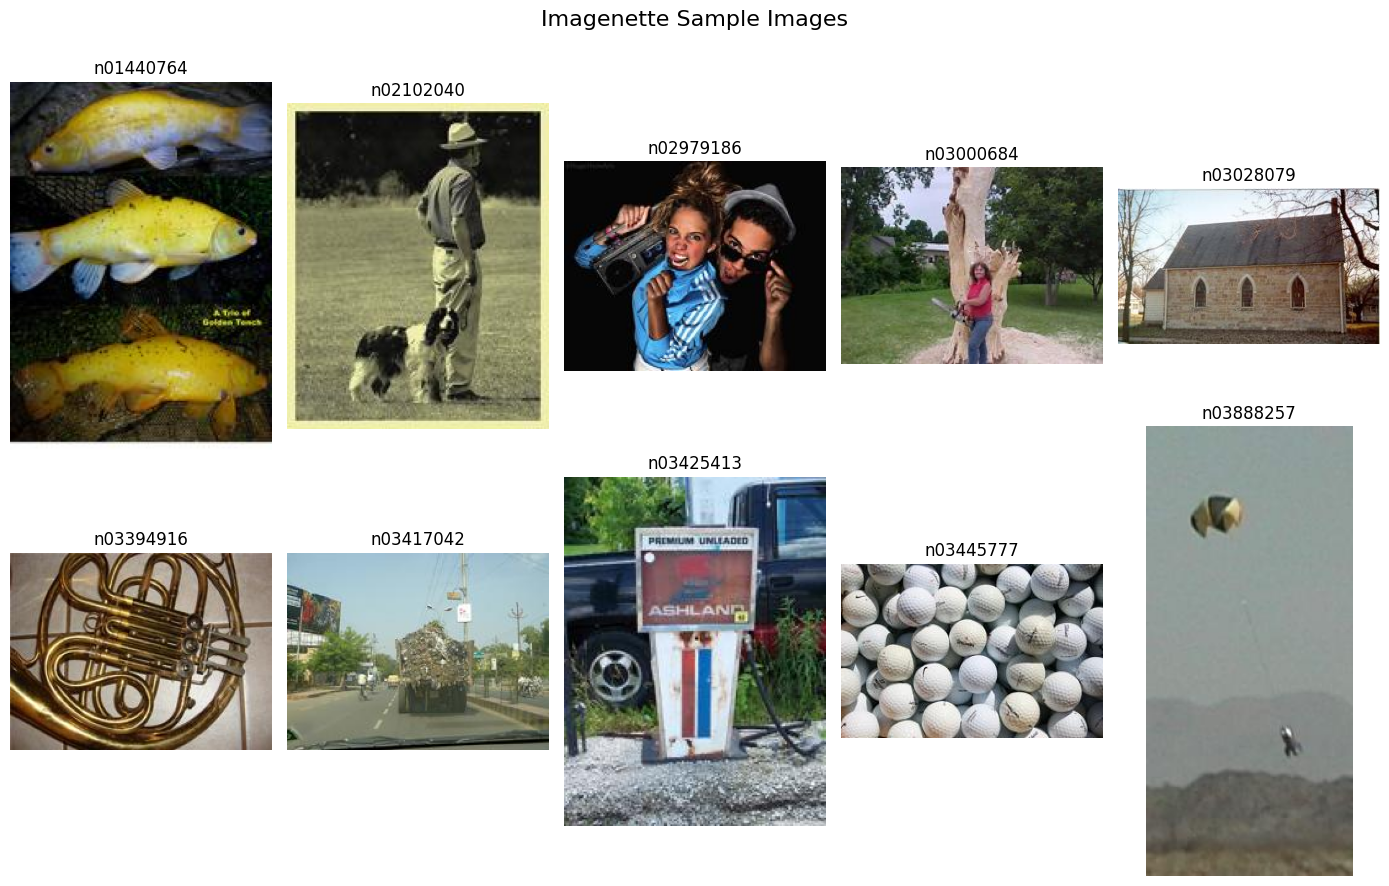

In [21]:
plt.figure(figsize=(14, 9))

image_count = 0

for class_name in classes:

    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    images = os.listdir(folder)

    if len(images) == 0:
        continue

    image_path = os.path.join(folder, images[0])

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 5, image_count + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

    image_count += 1

    if image_count == 10:
        break

plt.suptitle("Imagenette Sample Images", fontsize=16)
plt.tight_layout()
plt.show()

{'n01440764': 963, 'n02102040': 955, 'n02979186': 993, 'n03000684': 858, 'n03028079': 941, 'n03394916': 956, 'n03417042': 961, 'n03425413': 931, 'n03445777': 951, 'n03888257': 960}


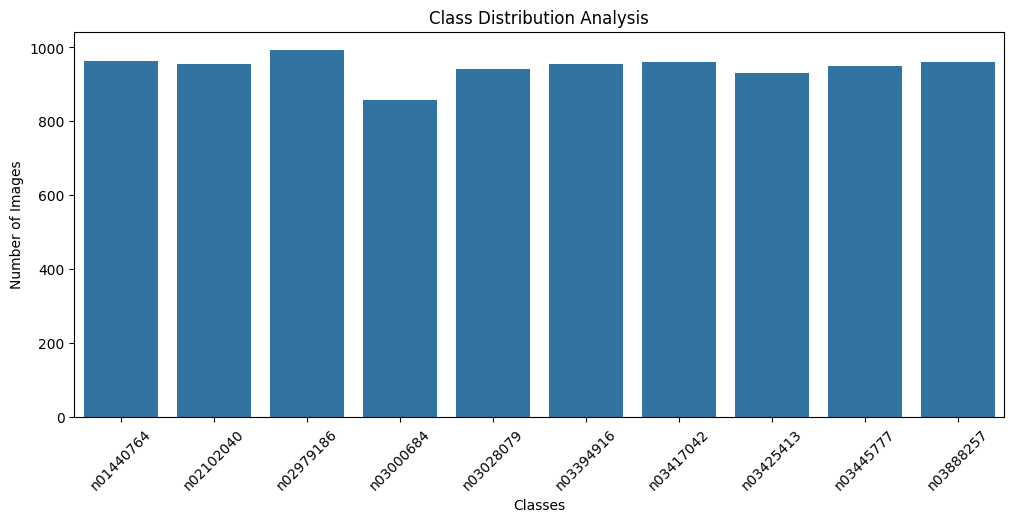

In [22]:
class_counts = {}

for class_name in classes:

    folder = os.path.join(dataset_path, class_name)

    if os.path.isdir(folder):

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png')
            )
        ]

        class_counts[class_name] = len(images)

print(class_counts)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=list(class_counts.keys()),
    y=list(class_counts.values())
)

plt.title("Class Distribution Analysis")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

In [23]:
quality_data = []

for class_name in classes:

    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    images = os.listdir(folder)

    for file in images[:100]:

        if not file.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        ):
            continue

        path = os.path.join(folder, file)

        img = cv2.imread(path)

        if img is not None:

            gray = cv2.cvtColor(
                img, cv2.COLOR_BGR2GRAY
            )

            sharpness = cv2.Laplacian(
                gray, cv2.CV_64F
            ).var()

            height, width = img.shape[:2]

            quality_data.append({
                "Class": class_name,
                "Image": file,
                "Width": width,
                "Height": height,
                "Sharpness": sharpness
            })

quality_df = pd.DataFrame(quality_data)

display(quality_df.head(10))

print("Images analysed:", len(quality_df))
print("Average sharpness:", quality_df["Sharpness"].mean())

,Class,Image,Width,Height,Sharpness
0,n01440764,n01440764_4409.JPEG,160,225,1284.303498
1,n01440764,n01440764_12069.JPEG,213,160,3097.091712
2,n01440764,n01440764_2866.JPEG,160,213,1068.405810
3,n01440764,n01440764_8084.JPEG,160,213,993.586847
4,n01440764,n01440764_11469.JPEG,213,160,1702.299708
5,n01440764,n01440764_5066.JPEG,240,160,3128.116086
6,n01440764,n01440764_4983.JPEG,213,160,3391.626512
7,n01440764,n01440764_4377.JPEG,213,160,3927.678791
8,n01440764,n01440764_7913.JPEG,160,244,1076.720390
9,n01440764,n01440764_9568.JPEG,213,160,852.864933


Images analysed: 1000
Average sharpness: 2041.234590976555


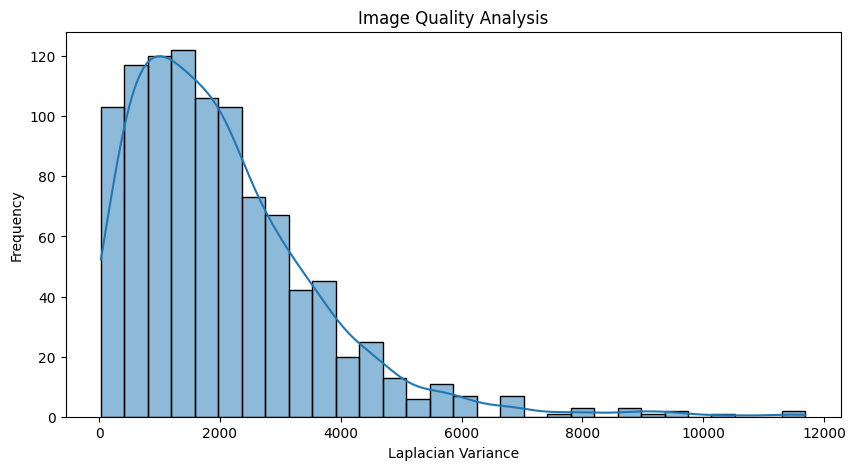

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    quality_df["Sharpness"],
    bins=30,
    kde=True
)

plt.title("Image Quality Analysis")
plt.xlabel("Laplacian Variance")
plt.ylabel("Frequency")

plt.show()

In [25]:
print("Image Resolution Analysis")

print("Average Width:", quality_df["Width"].mean())
print("Average Height:", quality_df["Height"].mean())

print("\nMinimum Width:", quality_df["Width"].min())
print("Maximum Width:", quality_df["Width"].max())

print("\nMinimum Height:", quality_df["Height"].min())
print("Maximum Height:", quality_df["Height"].max())

Image Resolution Analysis
Average Width: 205.536
Average Height: 175.71

Minimum Width: 160
Maximum Width: 543

Minimum Height: 160
Maximum Height: 479


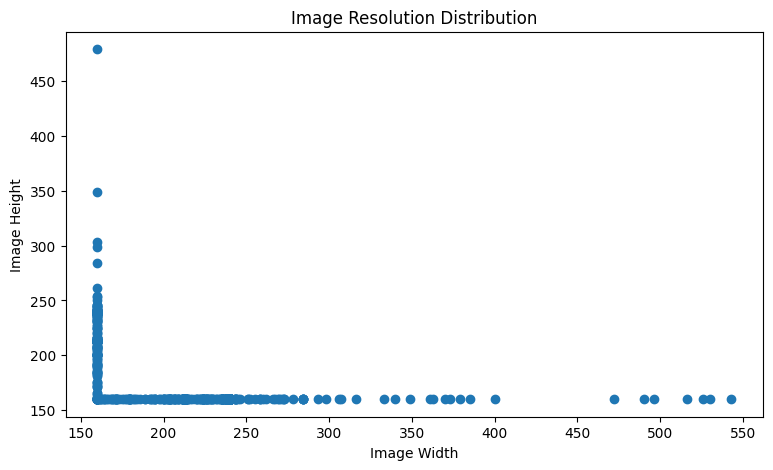

In [26]:
plt.figure(figsize=(9, 5))

plt.scatter(
    quality_df["Width"],
    quality_df["Height"]
)

plt.title("Image Resolution Distribution")
plt.xlabel("Image Width")
plt.ylabel("Image Height")

plt.show()

In [27]:
valid = 0
invalid = 0
unreadable = 0

for class_name in classes:

    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    for file in os.listdir(folder):

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)
            img.verify()

            if img.format not in ["JPEG", "PNG"]:
                invalid += 1
            else:
                valid += 1

        except Exception:
            unreadable += 1

print("Annotation and Image Validation")

print("Valid Images:", valid)
print("Invalid Images:", invalid)
print("Unreadable Images:", unreadable)

Annotation and Image Validation
Valid Images: 9469
Invalid Images: 0
Unreadable Images: 0


In [28]:
print("\n====================================")
print("       FINAL DATASET AUDIT")
print("====================================")

print("Dataset: Imagenette")

print("Total Classes:", len(class_counts))

print("Total Images:", sum(class_counts.values()))

print("\nCLASS DISTRIBUTION")

for name, count in class_counts.items():
    print(name, ":", count)

print("\nIMAGE QUALITY")

print("Average Sharpness:",
      round(quality_df["Sharpness"].mean(), 2))

print("\nIMAGE RESOLUTION")

print("Average Width:",
      round(quality_df["Width"].mean(), 2))

print("Average Height:",
      round(quality_df["Height"].mean(), 2))

print("\nIMAGE VALIDATION")

print("Valid Images:", valid)
print("Invalid Images:", invalid)
print("Unreadable Images:", unreadable)

print("\n====================================")
print("DATASET AUDIT COMPLETED!")
print("====================================")


       FINAL DATASET AUDIT
Dataset: Imagenette
Total Classes: 10
Total Images: 9469

CLASS DISTRIBUTION
n01440764 : 963
n02102040 : 955
n02979186 : 993
n03000684 : 858
n03028079 : 941
n03394916 : 956
n03417042 : 961
n03425413 : 931
n03445777 : 951
n03888257 : 960

IMAGE QUALITY
Average Sharpness: 2041.23

IMAGE RESOLUTION
Average Width: 205.54
Average Height: 175.71

IMAGE VALIDATION
Valid Images: 9469
Invalid Images: 0
Unreadable Images: 0

DATASET AUDIT COMPLETED!
